# Прогон обученной сети

Деталь → эмбеддинг и сила границ → нарезка по графу меша → метрики → картинки → сборка B-Rep → STEP.

**Источник** (`SOURCE` в первой ячейке):
- `"val:0"`, `"train:5"`, `"test:3"` — N-я деталь сплита из кэша: признаки и кольца уже посчитаны, есть разметка, поэтому считаются метрики и рисуется карта ошибок;
- uid детали из `dataset/data/cache`;
- у прогона на кусках (`configs/tile.yaml`, например `tile50`) деталь берётся целиком: тот же виртуальный скан CAD, что при сборке кэша, рабочий меш с ребром 0.3 мм, сеть по кускам (ядро 60 тысяч + кайма 72 кольца), одна нарезка на всю деталь (`src/inference.py`, `segment_tiles`; README, «Края кусков»). Скан и упрощение — минуты на деталь;
- путь к любому `.stl` / `.ply`, например к реальному скану: признаки считаются здесь же тем же конвейером (подложка → рабочий меш → струя), это от 10 секунд до минуты; разметки нет, только нарезка. У прогона на кусках файл — скан, а тесселяция CAD идёт через виртуальный сканер, если задан `SCAN_SEED`.

Ядро — `.venv`. GPU не обязателен: на CPU проход сети занимает десятки секунд вместо долей, сама нарезка идёт на CPU всегда.

In [1]:
import dataclasses
import os
import sys
import time
from collections import Counter

os.environ.setdefault("PYOPENGL_PLATFORM", "egl")   # рендер без дисплея
ROOT = os.path.expanduser("~/curv_ai_segm")
sys.path.insert(0, ROOT)

RUN = "tile50"               # прогон: его best.pt, а конфиг (разрешение, признаки, кэш) — из runs/<RUN>/train.sh 
SOURCE = "~/scan2cad/colouring_test/assets/1.stl"           # "сплит:номер", uid из кэша или путь к .stl / .ply ~/scan2cad/colouring_test/assets/Кривошип.stl"
SCAN_SEED = None            # прогон на кусках, вход-файл из CAD: семя виртуального сканера; None — файл уже скан
# Пороги нарезки; None — из конфига прогона (на 60 тысячах: 0.05 / 0.16 / 60).
METHOD = None               # нарезка: "watershed" — водораздел и слияние, "multicut" — граф границ без висячих вершин; None — из конфига
BETA = None                 # multicut: сдвиг, граница — где сила выше BETA; больше — режет охотнее (из конфига 0.04 — нейтраль для tile50)
DEPTH = None                # глубина водораздела: соседние бассейны раздельны, если перевал выше дна каждого на DEPTH
VETO = None                 # вето слияния: регионы не сливаются, если 1 − cos их средних эмбеддингов больше VETO;
                            # больше — сливается охотнее, кластеров меньше
MIN_REGION = None           # регионы мельче стольких треугольников поглощаются соседом
REFIT = True                # переподгонка с перенарезкой после нарезки (раздел 6а)

# Конфиг читается при первом импорте кода проекта, поэтому ставится раньше остальных импортов.
# Сменили RUN на прогон с другим конфигом — перезапустите ядро.
from src.runs import run_flags, thresholds, use_run
CONFIG = use_run(RUN)
FLAGS = run_flags(RUN)      # сплиты и правило узких граней прогона: "val:1" у abc15 — это abc_val

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import trimesh

from dataset import features as FE
from dataset import remesh as R
from dataset.cache import PARTS, SPLITS, load_part, part_dir
from src import arrangement as AR
from src import patches as PA
from src import brep as B
from src import constraints as CS
from src import fitting as FT
from src.refit import refit_partition
from src import metrics as M
from src import reconstruct as RC
from src import topology as TP
from src import visualization as viz
from src.config import CFG
from src.data import CachedParts, compress_curvature, part_meta, ring_indices, rule_labels, split_uids
from src.boundary import partition as PT
from src.boundary.config import BCFG
from src.boundary.model import BoundarySegNet, head_config
from src.inference import TILE_INPUT, fixed_edge_work, prepare, tile_outputs
from src.model import PRIMITIVE_TYPES
from src.surfaces import KINDS

# Повторный запуск этой ячейки не перечитывает уже загруженные модули проекта: если код на
# диске поменялся после старта ядра, ниже работала бы старая версия. Тогда — перезапуск ядра.
# время старта процесса ядра: такты от загрузки системы (поле 22 /proc/<pid>/stat) плюс её время
BOOT = next(int(l.split()[1]) for l in open("/proc/stat") if l.startswith("btime"))
KERNEL_START = BOOT + int(open(f"/proc/{os.getpid()}/stat").read().rsplit(")", 1)[1].split()[19]) / os.sysconf("SC_CLK_TCK")
stale = [name for name, mod in list(sys.modules.items())
         if (getattr(mod, "__file__", None) or "").startswith(ROOT) and os.path.getmtime(mod.__file__) > KERNEL_START]
if stale:
    raise RuntimeError(f"код проекта изменился после запуска ядра ({', '.join(sorted(stale))}): "
                       "перезапустите ядро и выполните ячейки заново")

CHECKPOINT = f"{ROOT}/runs/{RUN}/best.pt"   # вариант D: голова границ поверх основной сети
VARIANT = "noisy"           # вариант кэша
# Пороги нарезки по графу (глубина бассейна, слияние, вето, поглощение мелких регионов) и
# метрик — под разрешение конфига, как в обучении: на 60 тысячах грани от 10 треугольников,
# поглощение регионов мельче 60.
MIN_FACE, PARTITION = thresholds()
PARTITION = dataclasses.replace(PARTITION, **{k: v for k, v in dict(
    method=METHOD, beta=BETA, depth=DEPTH, veto=VETO, min_region=MIN_REGION).items() if v is not None})
AZIMS = (40, 220)           # поворот камеры вокруг вертикали, градусы; сколько значений — столько видов
ELEV = -40                   # наклон камеры: >0 — смотрим сверху, <0 — снизу, градусы
BREP_INPUTS = ("net", "truth")   # по чему собирать B-Rep: "net" — кластеры сети, "truth" — разметка
BREP_BUILDER = "patches"   # "patches" — выбором кусков (src/patches.py); "edges" — по рёбрам (src/brep.py); "cells" — по рёбрам, при неудаче разбиением
STEP_DIR = f"{ROOT}/outputs/step"   # куда писать STEP
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"прогон {RUN}, конфиг {CONFIG.name}, грани от {MIN_FACE} треугольников, нарезка {PARTITION.method}, "
      + (f"beta {PARTITION.beta}, " if PARTITION.method == "multicut" else f"глубина водораздела {PARTITION.depth}, ")
      + f"вето {PARTITION.veto}, "
      f"поглощение регионов мельче {PARTITION.min_region}, устройство {DEVICE}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
прогон tile50, конфиг tile.yaml, грани от 10 треугольников, нарезка watershed, глубина водораздела 0.05, вето 0.16, поглощение регионов мельче 60, устройство cuda


## 1. Модель

Сеть варианта D: энкодер и головы эмбеддинга и типа основной архитектуры плюс голова границ, которая на каждом ребре меша даёт вероятность «оба треугольника на одной грани».

Чекпоинт хранит, обучалась ли сеть с логарифмом на каналах кривизны. Если это расходится с конфигом, признаки на входе будут не те, на которых сеть училась, — поэтому такой чекпоинт не загружается.

In [2]:
state = torch.load(CHECKPOINT, map_location=DEVICE)
if state.get("log_curvature", False) != CFG.model.log_curvature:
    raise RuntimeError("чекпоинт обучен с другим преобразованием входа, чем задаёт конфиг")
model = BoundarySegNet(state["channels"], CFG.model.emb_size, head_config(BCFG.model, state["model"])).to(DEVICE)
model.load_state_dict(state["model"])
model.eval()
print(f"{os.path.relpath(CHECKPOINT, ROOT)}: эпоха {state['epoch']}, "
      f"IoU нарезки при сохранении {state.get('score', float('nan')):.3f}")

runs/tile50/best.pt: эпоха 48, IoU нарезки при сохранении 0.778


## 2. Деталь

In [3]:
def resolve(source):
    # деталь из кэша (uid или "сплит:номер"); None — значит, это путь к файлу
    head = source.split(":")[0]
    alias = {"train": FLAGS["train_split"], "val": FLAGS["val_split"],
             "test": FLAGS["val_split"].replace("val", "test")}
    if ":" in source and (head in alias or (SPLITS / f"{head}.txt").exists()):
        head = alias.get(head, head)               # "val" — сплит прогона, "abc_val" — как написано
        uids = split_uids(head, VARIANT)
        k = int(source.split(":")[1])
        if not 0 <= k < len(uids):
            raise ValueError(f"в кэше конфига {CONFIG.name} у сплита {head} {len(uids)} деталей, номера {k} нет")
        return uids[k]
    if (part_dir(source, VARIANT) / "meta.json").exists():
        return source
    return None


def load_file(source):
    path = os.path.expanduser(source)
    if not os.path.isfile(path):
        # trimesh на несуществующий путь отвечает «string is not a file» с обрезанным
        # расширением, и кажется, что дело в формате.
        near = sorted(f for f in os.listdir(os.path.dirname(path)) if f.lower().endswith((".stl", ".ply", ".obj"))) \
            if os.path.isdir(os.path.dirname(path)) else []
        raise FileNotFoundError(f"нет файла: {path}" + (f"; в этом каталоге есть: {near}" if near else ""))
    return trimesh.load(path, force="mesh")


uid = resolve(SOURCE)
title = uid or os.path.basename(SOURCE)
cores = None                               # ядро куска на треугольник — у прогона на кусках
t = time.perf_counter()
if CFG.tile:                               # целая деталь, сеть по кускам в следующей ячейке
    if uid is not None:                    # тот же скан, что при сборке кэша, разметка — с CAD
        cad = trimesh.load(str(PARTS / uid / "mesh.ply"), process=False)
        mesh = fixed_edge_work(cad, part_meta(uid, VARIANT)["seed"])
        raw_labels = R.transfer_labels(cad, np.load(PARTS / uid / "face_id.npy"), mesh)
        labels, types, _ = rule_labels(uid, raw_labels, np.asarray(mesh.face_adjacency), mesh.vertices, mesh.faces,
                                       FLAGS["narrow"])
    else:
        mesh = fixed_edge_work(load_file(SOURCE), SCAN_SEED)
        labels = types = None
    item = {"adjacency": np.asarray(mesh.face_adjacency), "n_faces": len(mesh.faces)}
    names = TILE_INPUT
    print(f"рабочий меш {'со сканом ' if uid is not None or SCAN_SEED is not None else ''}"
          f"за {time.perf_counter() - t:.0f} с")
elif uid is not None:                      # деталь датасета: признаки, кольца и разметка из кэша
    item = CachedParts([uid], VARIANT, narrow=FLAGS["narrow"])[0]
    work = load_part(uid, VARIANT)["work"]
    mesh = trimesh.Trimesh(work["vertices"], work["faces"], process=False)
    labels, types = item["labels"], item["types"]
    names = part_meta(uid, VARIANT)["feature_names"]
else:                                      # произвольный меш: признаки считаем сами, разметки нет
    # Как в src/inference.py: подложка, рабочий меш и признаки. Мешу прямо из CAD накладывается
    # шум обучения — сеть не видела идеально острых рёбер; нужен ли он, решается по самому мешу.
    mesh, x, names, noised = prepare(load_file(SOURCE))
    item = {"features": x, "rings": None, "adjacency": np.asarray(mesh.face_adjacency),
            "n_faces": len(mesh.faces)}
    labels = types = None
    print(f"признаки посчитаны за {time.perf_counter() - t:.0f} с; шум обучения "
          + ("наложен: меш без шума, похоже, прямо из CAD" if noised else "не нужен: меш со сканера"))

print(f"{title}: {len(mesh.faces)} треугольников, габарит {np.linalg.norm(mesh.extents):.1f} мм"
      + (f", граней B-Rep {len(np.unique(labels))}" if labels is not None else ", разметки нет"))

рабочий меш за 12 с
1.stl: 22104 треугольников, габарит 31.6 мм, разметки нет


## 3. Эмбеддинг и сила границ

Сеть выдаёт на каждый треугольник вектор из 128 чисел. После нормировки это точка на единичной сфере; треугольники одной грани должны лечь рядом, разных граней — далеко. Голова типа предсказывает тип поверхности под треугольником, голова границ — силу стыка `1 − P(одна грань)` на каждом ребре меша.

In [4]:
if CFG.tile:
    # Эмбеддинг, тип и сила ребра — из куска, в ядре которого треугольник; у ребра между ядрами — среднее двух.
    tile_seconds = {}
    z_np, logits_np, strength_np, cores = tile_outputs(mesh, model, seed=0, seconds=tile_seconds)
    z, strength = torch.from_numpy(z_np), torch.from_numpy(strength_np)
    logits = torch.from_numpy(logits_np).t().unsqueeze(0)
    type_pred = logits_np.argmax(1)
    print(f"кусков {cores.max() + 1}: " + ", ".join(f"{k} {v:.1f} с" for k, v in tile_seconds.items())
          + f"; стыковых рёбер (сила > 0.5) {float((strength > 0.5).float().mean()):.1%}")
else:
    x = torch.from_numpy(item["features"]).to(DEVICE).unsqueeze(0)
    edges = torch.from_numpy(np.asarray(item["adjacency"], dtype=np.int64)).to(DEVICE)
    t = time.perf_counter()
    with torch.no_grad():
        idx = ring_indices(item, DEVICE)
        emb, logits, edge = model(x, idx, edges)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    z = F.normalize(emb[0].t(), dim=1)                 # (треугольники, 128), точки на сфере
    strength = (1 - torch.sigmoid(edge)).reshape(-1)   # сила границы на ребре
    type_pred = logits[0].argmax(0).cpu().numpy()
    print(f"кольца {'из кэша' if item.get('rings') is not None else 'посчитаны на лету'}, "
          f"проход сети вместе с ними {(time.perf_counter() - t) * 1000:.0f} мс, "
          f"стыковых рёбер (сила > 0.5) {float((strength > 0.5).float().mean()):.1%}")

[W1119 14:27:34.884914316 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 25165824 bytes (free: 1966080, total: 12477988864).
[W1119 14:27:34.894692229 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 29360128 bytes (free: 6160384, total: 12477988864).
[W1119 14:27:34.905602679 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 33554432 bytes (free: 18743296, total: 12477988864).
[W1119 14:27:34.912536180 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 35651584 bytes (free: 33423360, total: 12477988864).
[W1119 14:27:34.919212340 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 37748736 bytes (free: 1966080, total: 12477988864).
[W1119 14:27:34.927374210 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on devi

OutOfMemoryError: CUDA out of memory. Tried to allocate 44.00 MiB. GPU 0 has a total capacity of 11.62 GiB of which 37.88 MiB is free. Process 1585127 has 11.05 GiB memory in use. Including non-PyTorch memory, this process has 524.00 MiB memory in use. Of the allocated memory 251.25 MiB is allocated by PyTorch, and 46.75 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

## 4. Нарезка

Нарезка идёт по графу меша, а не mean-shift по эмбеддингу: у граней B-Rep связные куски поверхности, и рез по рёбрам это соблюдает, а mean-shift — нет (README, «Голова границ»).

Три шага. **Водораздел**: регионы — бассейны поля силы границы; два бассейна остаются раздельными, если перевал между ними выше дна каждого не меньше чем на `depth`. Абсолютного порога «здесь внутренность грани» нет, поэтому узкое скругление, где сила нигде не мала, тоже получает свой регион. **Агломерация**: соседние регионы сливаются, пока средняя сила границы ниже `merge`, но не сливаются, если средние эмбеддинги разошлись больше `veto` — решает в основном вето. **Мелкие регионы** отдаются соседу с самой длинной общей границей.

**Multicut** (`METHOD = "multicut"`) вместо водораздела и агломерации: решается, какие рёбра меша — граница, и висячих концов у графа границ не бывает. У ребра вес — логарифм шансов «одна грань», сдвинутый на `BETA`; жадно стягивается пара регионов с наибольшей суммой весов по всей общей границе, пока она положительна. Поэтому одно провальное ребро на стыке не сливает грани, как низкий перевал у водораздела; вето по эмбеддингу и поглощение мелких — те же.


In [ ]:
t = time.perf_counter()
pred = PT.partition(len(mesh.faces), np.asarray(item["adjacency"]),
                    strength.double().cpu().numpy(), PARTITION,
                    z.cpu().numpy())
print(f"нарезка по графу: {(time.perf_counter() - t) * 1000:.0f} мс, "
      f"кластеров {pred.max() + 1}, пороги {PARTITION}")

нарезка по графу: 52 мс, кластеров 13, пороги PartitionCfg(method='watershed', beta=0.04, depth=0.05, merge=1.01, veto=0.16, min_region=60)


## 5. Метрики

Только для деталей из кэша — нужна разметка.

- **IoU** грани — пересечение её треугольников с лучшим совпадающим кластером, делённое на объединение; усредняется по граням. Грань с IoU ниже 0.5 считается потерянной.
- **Протечка** — грань, чей кластер уже достался другой: слияние N граней даёт N − 1. **Лишний разрез** — ещё один кусок уже покрытой грани.
- **Оракул** — нарезка, которой подсказали правильный ответ: каждый треугольник отдаётся ближайшему истинному центру своей грани в эмбеддинге. Это потолок для любой нарезки, которая смотрит только на эмбеддинг; разница с IoU нарезки — то, что теряет нарезка.

In [ ]:
if labels is None:
    print("разметки нет — метрики не считаются")
else:
    lab_t, pred_t = torch.from_numpy(labels), torch.from_numpy(pred)
    big = torch.bincount(lab_t)[lab_t] >= MIN_FACE
    s = M.segment_scores(lab_t[big], pred_t[big])
    ts = M.type_scores(logits[0].cpu(), torch.from_numpy(types), lab_t)
    zc = z.cpu()
    faces = lab_t.unique()
    cent = F.normalize(torch.zeros(int(lab_t.max()) + 1, zc.shape[1]).index_add_(0, lab_t, zc.float())[faces], dim=1)
    nearest = torch.cat([(c @ cent.t()).argmax(1) for c in zc.float().split(1 << 18)])   # порциями: у целой детали миллионы
    oracle = M.segment_scores(lab_t[big], faces[nearest][big])
    print(f"граней {s['faces']} (мельче {MIN_FACE} треугольников выброшены), кластеров {s['clusters']}")
    print(f"IoU нарезки {s['mean_iou']:.3f}, оракул {oracle['mean_iou']:.3f}")
    print(f"потеряно граней {s['missed_frac']:.0%}, протечек {s['leaks']:.0f}, "
          f"лишних разрезов {s['splits']:.0f}")
    print(f"тип поверхности верен на {ts['type_acc_tri']:.0%} треугольников, "
          f"{ts['type_acc_face']:.0%} граней")
    if cores is not None:
        sc = M.seam_cuts(np.asarray(item["adjacency"]), cores, labels, pred)
        print(f"шов ядер: внутри граней разрезано {sc['seam_cut']:.1%} рёбер на шве ({sc['seam_edges']}) "
              f"против {sc['inner_cut']:.1%} вдали от него")

разметки нет — метрики не считаются


## 6. Картинки

Кластер красится цветом той грани, для которой он основной. Поэтому верно найденная грань выглядит одинаково на обеих панелях, слияние — одним цветом на несколько граней, а лишний разрез — новым цветом внутри грани. На карте ошибок красным — треугольники, которые не попали в основной кластер своей грани. Сила границы `1 − P(одна грань)` живёт на рёбрах меша; треугольник красится наибольшей силой из своих рёбер, так узкая грань со скатами с двух сторон видна целиком.


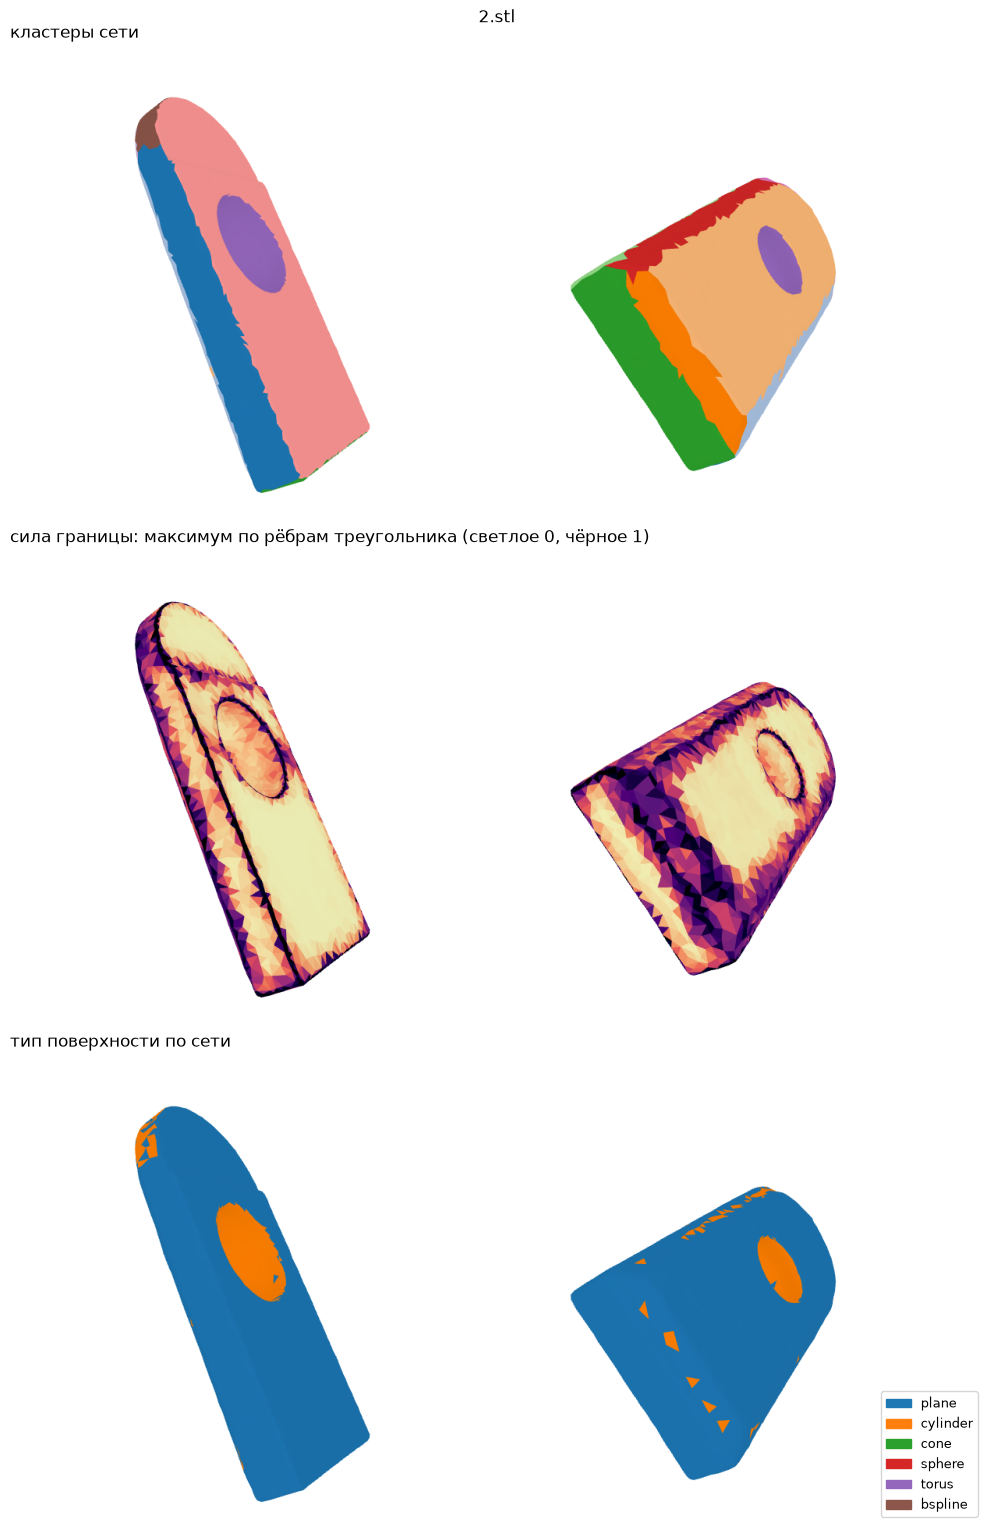

In [ ]:
def face_strength(m, s):
    # сила треугольника — наибольшая из сил его рёбер
    adj, out = np.asarray(m.face_adjacency), np.zeros(len(m.faces))
    for side in (0, 1):
        np.maximum.at(out, adj[:, side], s)
    return out


def strength_colors(s):
    return (plt.get_cmap("magma_r")(s) * 255).astype(np.uint8)


def palette(n, seed=0):
    # n различимых цветов RGBA: до десяти — tab10 (все тона разные), дальше
    # tab20, где цвета идут парами тёмный-светлый, и случайные. Для легенды из
    # пяти-шести подписей пары не годятся: светлый синий «sphere» глазом не
    # отличить от тёмного «plane» на освещённой картинке.
    base = plt.get_cmap("tab10" if n <= 10 else "tab20")(np.arange(10 if n <= 10 else 20))[:, :3]
    extra = np.random.default_rng(seed).uniform(0.15, 0.95, size=(max(n - len(base), 0), 3))
    rgb = np.vstack([base, extra])[:n]
    return (np.c_[rgb, np.ones(len(rgb))] * 255).astype(np.uint8)


panels = {}
if labels is not None:
    n_faces = labels.max() + 1
    face_col = palette(n_faces)
    panels["грани B-Rep (разметка)"] = face_col[labels]
    overlap = M.overlap(torch.from_numpy(labels), torch.from_numpy(pred)).numpy()
    main_of_face = overlap.argmax(1)
    clu_col = palette(pred.max() + 1 + n_faces, seed=1)[n_faces:]
    for f in np.unique(labels):
        clu_col[main_of_face[f]] = face_col[f]
    panels["кластеры сети"] = clu_col[pred]
    wrong = pred != main_of_face[labels]
    err = np.tile(np.array([225, 225, 225, 255], np.uint8), (len(pred), 1))
    err[wrong] = (215, 40, 40, 255)
    panels[f"ошибки: {wrong.mean():.0%} треугольников не в своём кластере"] = err
else:
    panels["кластеры сети"] = palette(pred.max() + 1)[pred]
panels["сила границы: максимум по рёбрам треугольника (светлое 0, чёрное 1)"] = strength_colors(
    face_strength(mesh, strength.double().cpu().numpy()))
type_col = palette(len(PRIMITIVE_TYPES), seed=2)
panels["тип поверхности по сети"] = type_col[type_pred]

fig, axes = plt.subplots(len(panels), len(AZIMS),
                         figsize=(5.2 * len(AZIMS), 5.2 * len(panels)), squeeze=False)
for r, (name, cols) in enumerate(panels.items()):
    for c, az in enumerate(AZIMS):
        axes[r, c].imshow(viz.render(mesh, cols, size=600, azim=az, elev=ELEV))
        axes[r, c].set_axis_off()
    axes[r, 0].set_title(name, loc="left")
axes[-1, -1].legend([plt.Rectangle((0, 0), 1, 1, color=type_col[i, :3] / 255)
                     for i in range(len(PRIMITIVE_TYPES))], PRIMITIVE_TYPES,
                    loc="lower right", fontsize=9)
fig.suptitle(title)
plt.tight_layout()
plt.show()

## 6а. Переподгонка с перенарезкой

Как подгонка по клику в ScanRuler: кластеры нарезки от меньших к большим; в самой глубокой точке кластера по пятну вокруг неё подгоняется примитив типа, за который голосует сеть (отсечение 3σ), и от неё идёт рост — треугольник берётся, если он в полосе 3.5σ у примитива и нормаль согласна (25° плоскость, 32° цилиндр/конус/тор, 38° сфера); примитив переподгоняется каждый круг, пока область растёт; переходная полоса скруглённого края срезается. Взятое закрепляется, бо́льшим кластерам не достаётся: лишний разрез дорастает до целой грани, у слипшегося кластера примитив забирает свою часть; ничьи куски с телом подгоняются ещё раз, остальное (полосы у скруглённых рёбер) уходит соседу с ближайшим примитивом. Не подогнанные кластеры (сплайны) остаются как были (`src/refit.py`; README, «Переподгонка с перенарезкой»).

Панели: кластеры до и после, красным — треугольники, у которых сменился кластер (у их нового кластера основной старый — другой).

переподгонка 1 с: кластеров 13 -> 13, подогнано 8, как было 5, кусков остатка 0, допуск 0.040 мм


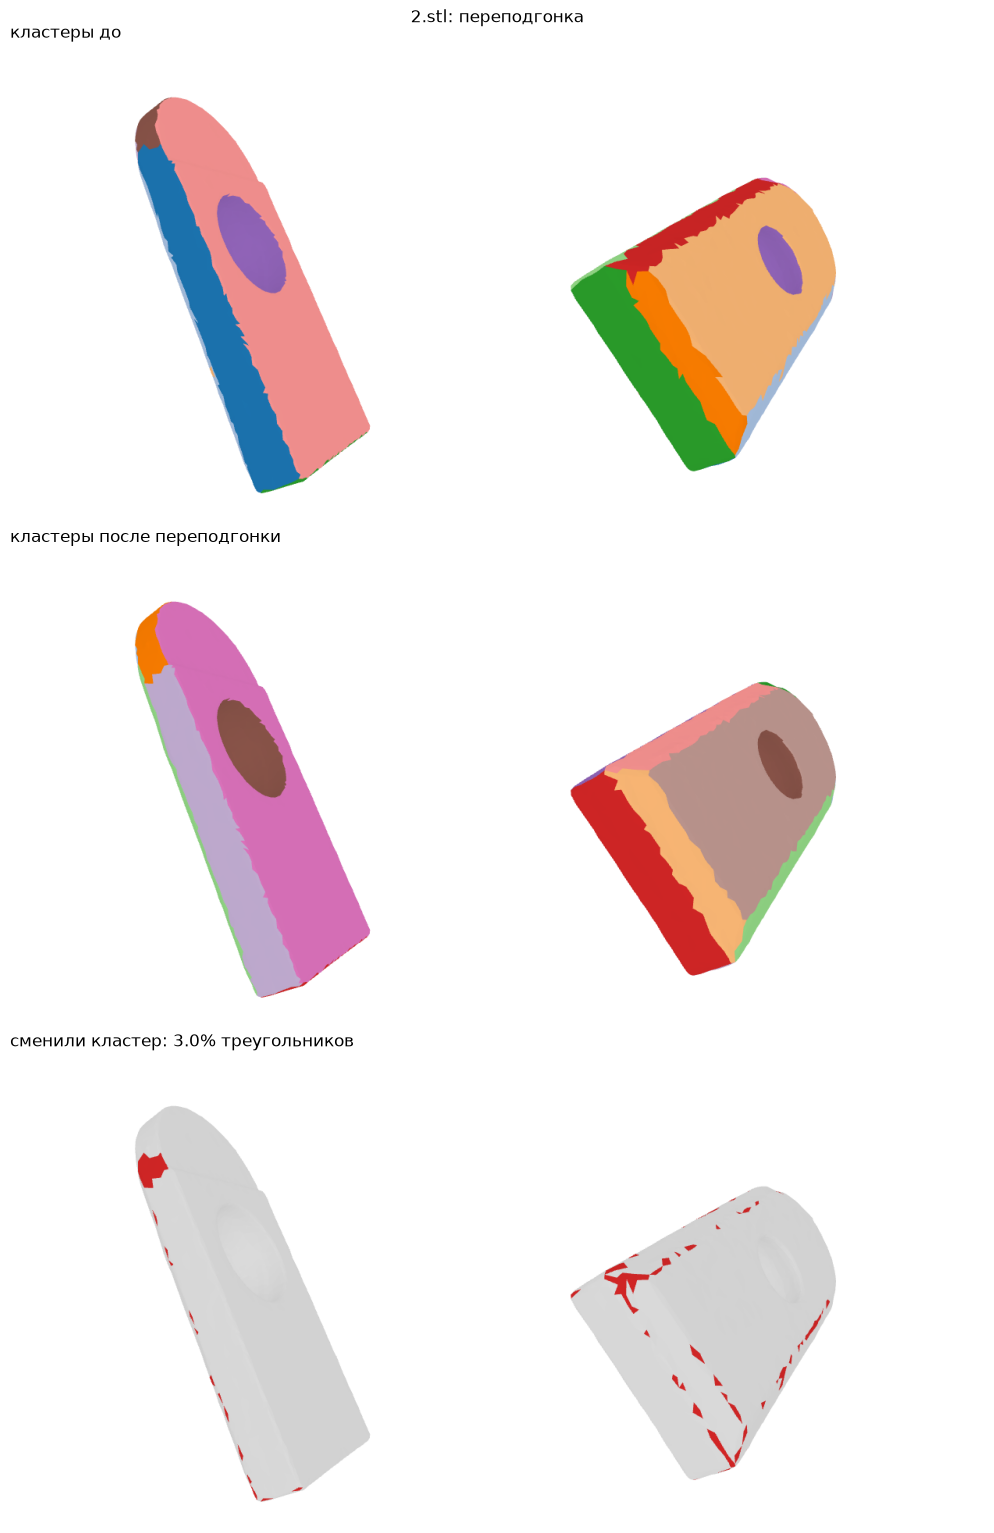

In [ ]:
if not REFIT:
    print("REFIT = False — пропущено")
else:
    t = time.perf_counter()
    refit, info = refit_partition(mesh.vertices, mesh.faces, item["adjacency"], pred, type_pred, CFG.brep,
                                  PARTITION.min_region)
    print(f"переподгонка {time.perf_counter() - t:.0f} с: кластеров {info['clusters_before']} -> {info['clusters_after']}, "
          f"подогнано {info['fitted']}, как было {info['kept']}, кусков остатка {info['leftovers']}, "
          f"допуск {info['tolerance']:.3f} мм")
    if labels is not None:
        for name, p in (("до", pred), ("после", refit)):
            s = M.segment_scores(lab_t[big], torch.from_numpy(p)[big])
            print(f"{name}: IoU {s['mean_iou']:.3f}, потеряно граней {s['missed_frac']:.0%}, протечек {s['leaks']:.0f}, "
                  f"лишних разрезов {s['splits']:.0f}, кластеров {s['clusters']}")

    def cluster_colors(p):
        # как в разделе 6: у детали с разметкой кластер красится цветом грани, для которой он основной
        if labels is None:
            return palette(p.max() + 1)[p]
        main = M.overlap(torch.from_numpy(labels), torch.from_numpy(p)).numpy().argmax(1)
        col = palette(p.max() + 1 + n_faces, seed=1)[n_faces:]
        for f in np.unique(labels):
            col[main[f]] = face_col[f]
        return col[p]

    old_of_new = M.overlap(torch.from_numpy(refit), torch.from_numpy(pred)).numpy().argmax(1)
    moved = old_of_new[refit] != pred
    diff = np.tile(np.array([225, 225, 225, 255], np.uint8), (len(pred), 1))
    diff[moved] = (215, 40, 40, 255)
    rows = {"кластеры до": cluster_colors(pred), "кластеры после переподгонки": cluster_colors(refit),
            f"сменили кластер: {moved.mean():.1%} треугольников": diff}
    fig, axes = plt.subplots(len(rows), len(AZIMS), figsize=(5.2 * len(AZIMS), 5.2 * len(rows)), squeeze=False)
    for r, (name, cols) in enumerate(rows.items()):
        for c, az in enumerate(AZIMS):
            axes[r, c].imshow(viz.render(mesh, cols, size=600, azim=az, elev=ELEV))
            axes[r, c].set_axis_off()
        axes[r, 0].set_title(name, loc="left")
    fig.suptitle(f"{title}: переподгонка")
    plt.tight_layout()
    plt.show()


## 7. Эмбеддинг в двух измерениях

Проекция 128-мерных точек на две главные компоненты. Это грубый взгляд: разные грани могут наложиться на плоскости, оставаясь разделёнными в полном пространстве, — судить по метрикам, а не по этой картинке.

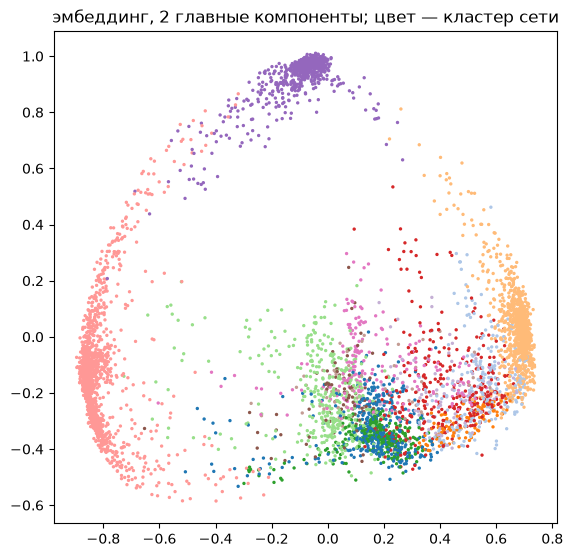

In [ ]:
sel = np.random.default_rng(0).choice(len(pred), min(6000, len(pred)), replace=False)
zs = z[sel].cpu()
_, _, v = torch.pca_lowrank(zs, q=2)
xy = ((zs - zs.mean(0)) @ v[:, :2]).numpy()
if labels is not None:
    dot_col, what = palette(labels.max() + 1)[labels[sel]], "грань разметки"
else:
    dot_col, what = palette(pred.max() + 1)[pred[sel]], "кластер сети"
plt.figure(figsize=(6.5, 6.5))
plt.scatter(xy[:, 0], xy[:, 1], s=2, c=dot_col[:, :3] / 255)
plt.title(f"эмбеддинг, 2 главные компоненты; цвет — {what}")
plt.gca().set_aspect("equal")
plt.show()

## 8. Признаки, которые видит сеть

Те же панели, что в `preview.ipynb`: `‖S‖` — 1-я производная нормали (ноль на плоскости, `1/R` на цилиндре), `κ₁`, `κ₂` со знаком, `‖∇II‖` — 2-я производная нормали (всплеск на стыке граней).

Значения — ровно те, что идут в сеть: из кэша или посчитанные для файла, после знакового логарифма, если сеть с ним обучалась. Шкала каждой панели обрезана по 2 и 98 перцентилю. Строка на канал и масштаб, столбец на ракурс.

In [ ]:
from src.data import CURVATURE_PREFIXES

# Как в preview.ipynb: канал -> (подпись, карта цветов).
PANELS = {"S": ("‖S‖ — 1-я произв. нормали", "viridis"),
          "k1": ("κ₁ со знаком", "coolwarm"),
          "k2": ("κ₂ со знаком", "coolwarm"),
          "dII": ("‖∇II‖ — 2-я произв. нормали", "magma")}
scale_txt = "sign·log1p" if CFG.model.log_curvature else "линейно"
scales = sorted({float(n.split("@")[1]) for n in names if n.startswith(CURVATURE_PREFIXES)})
rows = [(f"{ch}@{h:g}", h, *PANELS[ch]) for h in scales for ch in PANELS if f"{ch}@{h:g}" in names]

if not rows:
    print("у прогона нет каналов кривизны (кэш без струи) — показывать нечего")
else:
    fig, axes = plt.subplots(len(rows), len(AZIMS),
                             figsize=(5.2 * len(AZIMS) + 1, 5.2 * len(rows)), squeeze=False)
    for r, (ch, h, label, cmap) in enumerate(rows):
        values = item["features"][names.index(ch)]
        lo, hi = np.percentile(values, [2, 98])
        cols = viz.face_colors(np.clip(values, lo, hi), np.asarray(mesh.faces), cmap=cmap,
                               per_face=True, lo=0, hi=100)
        for c, az in enumerate(AZIMS):
            axes[r, c].imshow(viz.render(mesh, cols, azim=az, elev=ELEV))
            axes[r, c].set_axis_off()
        axes[r, 0].set_title(f"{label}, {scale_txt}, масштаб {h:g}·√A\n"
                             f"от {values.min():.2f} до {values.max():.2f}, медиана {np.median(values):.2f}",
                             loc="left", fontsize=10)
        fig.colorbar(mpl.cm.ScalarMappable(mpl.colors.Normalize(lo, hi), mpl.colormaps[cmap]),
                     ax=axes[r, :].tolist(), shrink=0.6, pad=0.01)
    fig.suptitle(title)
    plt.show()


у прогона нет каналов кривизны (кэш без струи) — показывать нечего


## 9. Сборка B-Rep и экспорт STEP

Кластеры → примитивы → тело → STEP (README, «Реконструкция B-Rep», «Сборка разбиением», «Оценка по корпусу»).

**Как устроена сборка разбиением и почему так.**
- *Топология не берётся с меша.* Поверхности, продлённые на весь габарит детали, режут его на ячейки. Граница истинного тела лежит на этих поверхностях, поэтому тело — объединение ячеек, а каждая ячейка целиком внутри или снаружи. Оболочка замкнута по построению: ошибка подгонки портит форму, но не оставляет дыр. Сборка по рёбрам, где каждое ребро строится по границе на меше, замыкала тело примерно у 4% деталей теста.
- *Лишняя поверхность почти безвредна, недостающая — нет.* Лишняя только добавляет разрезы, куски одной поверхности потом сливаются. Без нужной поверхности ячейки по обе стороны её грани срастаются. Поэтому кластер без примитива в допуске получает приближённый, а мелкие кластеры подгоняются от 3 треугольников.
- *Ячейку выбирает доля её объёма внутри меша*, оценённая по равномерным точкам всей коробки с тем же вектором знаков относительно поверхностей: голос точек самой ячейки (центр, вершины) смещён к детали и брал лишние ячейки.
- *Склейка ячеек с `Glue` и сверка объёма на каждом шаге*: без них OCC падал или молча терял тело.
- *Касания, соосность, параллельность* — та же совместная подгонка при точных условиях, что у сборки по рёбрам (9.2): без неё касание в теле лишь приближённое.

На 593 деталях теста (кэш `aug60`) по разметке собирается 55.6% деталей, по нарезке сети — 48.7%; одно валидное тело — у ~90%. «Собрана» — критерий из 9.5.

`BREP_BUILDER` в первой ячейке — как собирать:
- `"cells"` — разбиением (`src/arrangement.py`);
- `"edges"` — по рёбрам (`src/brep.py`): непостроенное ребро оставляет дыру; оставлено для сравнения.

`BREP_INPUTS` — по чему собирать; каждый вход проходит все шаги и пишет свой STEP:
- `"net"` — кластеры сети;
- `"truth"` — разметка B-Rep на том же рабочем меше: видно, что теряет сама сборка, без ошибок нарезки.

Оба входа — один и тот же рабочий меш, отличаются только кластеры. Разметка есть только у деталей из кэша.

In [ ]:
CELLS = BREP_BUILDER == "cells"
# Сборке разбиением потерянная поверхность дороже лишней: мелкие кластеры не отдаются соседу.
brep_cfg = dataclasses.replace(CFG.brep, min_triangles=AR.MIN_TRIANGLES) if CELLS else CFG.brep
brep_runs = {}   # вход -> (меш, кластер на треугольник, тип на треугольник, конфиг сборки)
for name in BREP_INPUTS:
    if name == "net":
        brep_runs[name] = (mesh, pred, type_pred, brep_cfg)
    elif uid is None:
        print(f"{name}: у произвольного меша разметки нет — пропущено")
    elif name == "truth":
        brep_runs[name] = (mesh, labels, types, brep_cfg)
    else:
        raise ValueError(f"неизвестный вход сборки {name!r}")
# осколки ремеша — несвязные куски меньше 1% треугольников — в сборку не идут: у их кластеров нет ни соседей, ни рёбер
brep_runs = {name: (*TP.main_parts(m, seg, votes), cfg) for name, (m, seg, votes, cfg) in brep_runs.items()}
for name, (m, seg, _, _) in brep_runs.items():
    print(f"{name}: {len(m.faces)} треугольников, {len(m.vertices)} вершин, кластеров {len(np.unique(seg))}")


truth: у произвольного меша разметки нет — пропущено
net: 5412 треугольников, 2706 вершин, кластеров 13


### 9.1 Подгонка примитивов

Каждому кластеру — примитив того типа, за который голосует сеть (у разметки — истинный тип). Старт подгонки — `fits.py`, затем все параметры уточняются вместе по взвешенному точному расстоянию. Конус почти без раствора (меньше 1°) подгоняется цилиндром, почти плоский (больше 89°) — плоскостью. Если голоса нет или этот тип не подогнался, типы перебираются от простого к сложному, и следующий заменяет текущий, только если уменьшает взвешенную RMS больше чем втрое (`KIND_RMS_RATIO`). Точки — вершины кластера без полосы у границы. Мелкие кластеры отдаются соседу; соседние кластеры одного типа сливаются, если общий примитив в допуске для каждой части — так чинятся лишние разрезы.

Соседние плоскости с углом меньше 5°, точки каждой из которых лежат на плоскости другой (RMS не больше трёх допусков), сливаются в одну грань: прямая пересечения почти параллельных плоскостей уходит далеко от их общей границы, и ребро не строится.


In [ ]:
brep_fits = {}
for name, (m, seg, votes, cfg) in brep_runs.items():
    t = time.perf_counter()
    seg_fit, surfaces, fit_info = FT.fit_clusters(np.asarray(m.vertices, np.float64), np.asarray(m.faces),
                                                  np.asarray(m.face_adjacency), seg, votes, cfg)
    brep_fits[name] = (seg_fit, surfaces, fit_info)
    print(f"{name}: подгонка {time.perf_counter() - t:.1f} с, допуск RMS {fit_info['tolerance']:.3f} мм")
    print(f"  кластеров {fit_info['clusters']}, слито лишних разрезов {fit_info['merges']}, "
          f"почти копланарных плоскостей слито {fit_info['coplanar']}, "
          f"поверхностей {len(surfaces)}: "
          + ", ".join(f"{k} {v}" for k, v in Counter(s.kind for s in surfaces.values()).items()))
    print(f"  без примитива {len(fit_info['unfitted'])}, вне допуска RMS {len(fit_info['approximate'])}")


net: подгонка 0.1 с, допуск RMS 0.040 мм
  кластеров 13, слито лишних разрезов 0, почти копланарных плоскостей слито 0, поверхностей 13: plane 10, cylinder 3
  без примитива 0, вне допуска RMS 5


### 9.2 Соотношения соседей

Сначала кластеры без единого участка границы (узкая грань, у которой все участки короче `min_chain_edges` и стянуты в узлы) отдаются соседу: рёбер у такой грани не будет, и на её месте осталась бы дыра.

Параллельность осей и нормалей, соосность и касание ищутся по параметрам соседних поверхностей. Связанные соотношениями поверхности подгоняются к своим точкам совместно, при точных условиях: у почти касательной пары пересечение численно вырождено, а в CAD касание должно быть точным. Соотношение, от которого RMS поверхности вырастает больше чем в `rms_growth` раз и выходит за допуск, отбрасывается. Поиск повторяется на уже подогнанных поверхностях, пока находятся новые соотношения: соосность короткого пояса видна только после того, как выровнены оси.

Нужно обеим сборкам. Без этого шага сборка разбиением даёт тело в допуске по форме, но касание в нём лишь приближённое: на месте скругления — микроступенька или щепка [3 детали теста по разметке, точных касаний из истинных: 0/10, 0/18, 0/8 без шага, 10/10, 16/18, 8/8 с ним].

In [ ]:
brep_geometry = {}
for name, (m, _, _, cfg) in brep_runs.items():
    seg_fit, surfaces, fit_info = brep_fits[name]
    t = time.perf_counter()
    # кластер, у которого все участки границы короче min_chain_edges, рёбер не получит — отдаётся соседу
    seg_fit, bounds, chainless = TP.drop_chainless(m, seg_fit, cfg.min_chain_edges)
    surfaces = {l: s for l, s in surfaces.items() if l not in chainless}
    brep_fits[name] = (seg_fit, surfaces, fit_info)
    fit_samples = FT.samples(seg_fit, np.asarray(m.face_adjacency), np.asarray(m.vertices, np.float64),
                             np.asarray(m.faces), surfaces, cfg)
    # поиск соотношений и совместная подгонка по кругу, пока находятся новые
    chained = {ch.pair for ch in bounds.chains}
    touching = TP.touching(m, seg_fit)
    surfaces, relations, dropped = CS.settle(surfaces, chained | touching, fit_samples,
                                             fit_info["tolerance"], cfg, short=touching - chained)
    brep_geometry[name] = (surfaces, relations, bounds)
    print(f"{name}: {time.perf_counter() - t:.1f} с; участков границ {len(bounds.chains)}, узлов {len(bounds.nodes)}, "
          f"кластеров без рёбер отдано соседу {len(chainless)}")
    print("  принято:", dict(Counter(r.name for r in relations)))
    print("  отброшено:", dict(Counter(r.name for r in dropped)))


net: 0.2 с; участков границ 29, узлов 17, кластеров без рёбер отдано соседу 0
  принято: {'axis_along_normal': 2, 'axis_in_plane': 3, 'plane_offset': 2}
  отброшено: {'axis_along_normal': 1}


### 9.3 Сборка и экспорт

**Выбором кусков** (`patches.build`, по умолчанию; по мотивам Point2CAD и Mesh2Brep). Каждая поверхность — кусок вокруг своего кластера с запасом в 10 рёбер меша (почти совпадающие плоскости — один кусок); все куски режутся друг другом одной булевой операцией OCC. Какие кусочки войдут в тело, решает целочисленная задача: на каждом ребре 0 или 2 выбранных кусочка, обходящих его в противоположные стороны; награда — площадь, покрытая своим кластером в верной ориентации, штраф — площадь вдали от меша. Замкнутость — условие задачи, а не результат того, что сошлись все рёбра по отдельности.

**По рёбрам с соседями** (`brep.build`). Каждая грань ограничена только кривыми с соседними кластерами: касательный стык — аналитической линией касания, соосная пара — окружностью, остальные — ветвью пересечения, ближайшей к общей границе кластеров на меше. Узел границы → вершина, рёбра кластера → грань, грани с общими рёбрами → оболочка → тело. Грани чистые, касания точные.

**Разбиением** (`arrangement.build`) — если по рёбрам тело не замкнулось, невалидно или его объём расходится с мешем больше чем на 2%. Поверхности на всю коробку режут её на ячейки, тело — ячейки внутри меша. Замыкается всегда, но грани поделены следами чужих поверхностей.

`BREP_BUILDER = "edges"` — только по рёбрам, без запасного пути. В сводке — каким способом собрано.

In [ ]:
os.makedirs(STEP_DIR, exist_ok=True)
brep_shapes, brep_reports = {}, {}
for name, (m, _, _, cfg) in brep_runs.items():
    seg_fit = brep_fits[name][0]
    surfaces, relations, bounds = brep_geometry[name]
    t = time.perf_counter()
    if BREP_BUILDER == "patches":
        shape, report = PA.build(m, seg_fit, surfaces, relations, fit_info["tolerance"])
    elif CELLS:
        shape, report = RC.solid(m, seg_fit, surfaces, relations, bounds, cfg)
    else:
        shape, report = B.build(m, seg_fit, surfaces, relations, bounds, cfg)
    print(f"{name}: сборка {time.perf_counter() - t:.1f} с")
    for key, value in report.items():
        print(f"  {key}: {value}")
    if shape is None:
        print("  не построено ни одной грани — экспортировать нечего")
        continue
    brep_shapes[name] = shape
    brep_reports[name] = report
    step_path = f"{STEP_DIR}/{os.path.splitext(title)[0]}_{name}_{BREP_BUILDER}.step"
    print(("  записан " if B.write_step(shape, step_path) else "  НЕ записан ") + step_path)


net: сборка 0.3 с
  почти совпадающих плоскостей объединено: 0
  кусков: 13
  линий касания: 2
  кусочков: 231
  кусочков выбрано: 22
  решатель: 0; цель -0.9537
  покрытых кусочков запрещено: 0
  покрытых кусочков не выбрано: 2
  доля покрытой площади вне тела: 0.045705514107461924
  поверхностей без кусочка: 0
  оболочек: 1
  тело: True
  граней: 22
  валидна: True
  записан /home/daniil/curv_ai_segm/outputs/step/2_net_patches.step


### 9.4 Картинки

На каждый вход две строки: кластеры, по которым шла сборка, цветом по типу примитива (серые — без примитива), и собранная форма, тесселированная обратно в меш.

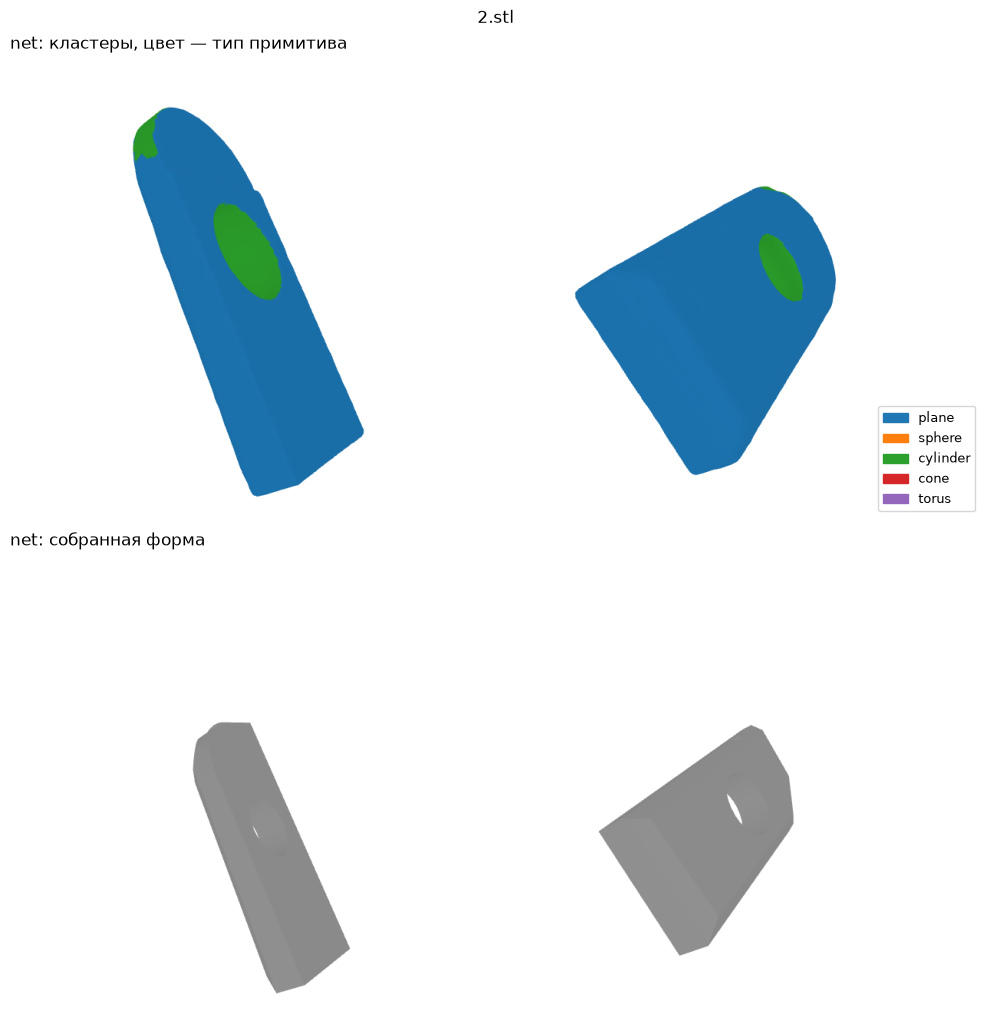

In [ ]:
kind_col = palette(len(KINDS), seed=3)
names = [n for n in brep_runs if n in brep_shapes]
tessellated = {n: B.tessellate(brep_shapes[n], 0.002 * np.linalg.norm(brep_runs[n][0].extents)) for n in names}
for n in [n for n in names if len(tessellated[n].faces) == 0]:
    print(f"{n}: у собранной формы нет ни одной тесселированной грани — не показывается")
names = [n for n in names if len(tessellated[n].faces)]
if not names:
    print("тел нет — показывать нечего")
else:
    fig, axes = plt.subplots(2 * len(names), len(AZIMS), figsize=(5.2 * len(AZIMS), 5.2 * 2 * len(names)),
                             squeeze=False)
    for r, name in enumerate(names):
        m = brep_runs[name][0]
        seg_fit, surfaces, _ = brep_fits[name]
        cols = np.tile(np.array([190, 190, 190, 255], np.uint8), (len(seg_fit), 1))
        for l, s in brep_geometry[name][0].items():
            cols[seg_fit == l] = kind_col[KINDS.index(s.kind)]
        result = tessellated[name]
        for c, az in enumerate(AZIMS):
            axes[2 * r, c].imshow(viz.render(m, cols, size=600, azim=az, elev=ELEV))
            axes[2 * r + 1, c].imshow(viz.render(result, None, size=600, azim=az, elev=ELEV))
            axes[2 * r, c].set_axis_off()
            axes[2 * r + 1, c].set_axis_off()
        axes[2 * r, 0].set_title(f"{name}: кластеры, цвет — тип примитива", loc="left")
        axes[2 * r + 1, 0].set_title(f"{name}: собранная форма", loc="left")
    axes[0, -1].legend([plt.Rectangle((0, 0), 1, 1, color=kind_col[i, :3] / 255) for i in range(len(KINDS))],
                       KINDS, loc="lower right", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### 9.5 Сверка с CAD

Только для деталей из кэша: истинная геометрия — тесселяция STEP детали (`mesh_full.ply`). Тот же критерий, что в `scripts/evaluate_brep.py`. Деталь **собрана**, если:
- одно тело и BRepCheck его принимает — дыр нет;
- p95 расстояний от точки до поверхности между телом и CAD в обе стороны не больше 0.005 √площади (~0.12 мм на медианной детали) — на уровне отклонения самого рабочего меша от CAD;
- объём расходится с рабочим мешем или с CAD, с тем, с которым ближе, не больше 2%.

На картинке: CAD, где тела рядом нет, — красным (потерянное), тело, где рядом нет CAD, — синим (лишнее).

In [ ]:
sys.path.insert(0, f"{ROOT}/scripts")
from evaluate_brep import DEVIATION_REL, fidelity, part_file, passed

if uid is None:
    print("у произвольного меша CAD нет — сверка пропущена")
else:
    cad = trimesh.load(part_file(uid, "mesh_full.ply"), process=False)
    brep_checks = {}
    for name, shape in brep_shapes.items():
        m = brep_runs[name][0]
        r = {**brep_reports[name], **fidelity(shape, m), **fidelity(shape, cad, "cad_")}
        brep_checks[name] = r
        print(f"{name}: {'СОБРАНА' if passed(r) else 'не собрана'} — тел {r.get('тел')}, валидна {r.get('валидна')}, "
              f"отклонение от CAD p95 {r['cad_dev_mesh']:.4f} / {r['cad_dev_shape']:.4f} √площади "
              f"(порог {DEVIATION_REL}), объём: от меша {r['volume_err']:.1%}, от CAD {r['cad_volume_err']:.1%}")

у произвольного меша CAD нет — сверка пропущена


In [ ]:
if uid is not None and brep_shapes:
    names = list(brep_shapes)
    fig, axes = plt.subplots(len(names), 2 * len(AZIMS), figsize=(4.2 * 2 * len(AZIMS), 4.4 * len(names)),
                             squeeze=False)
    scale = np.sqrt(mesh.area)
    for r, name in enumerate(names):
        result = B.tessellate(brep_shapes[name], 1e-3 * scale)
        lost = trimesh.proximity.closest_point(result, cad.triangles_center)[1] / scale > DEVIATION_REL
        extra = trimesh.proximity.closest_point(cad, result.triangles_center)[1] / scale > DEVIATION_REL
        cad_col = np.tile(np.array([200, 200, 200, 255], np.uint8), (len(cad.faces), 1))
        cad_col[lost] = (215, 40, 40, 255)
        res_col = np.tile(np.array([200, 200, 200, 255], np.uint8), (len(result.faces), 1))
        res_col[extra] = (40, 60, 215, 255)
        for c, az in enumerate(AZIMS):
            axes[r, 2 * c].imshow(viz.render(cad, cad_col, size=500, azim=az, elev=ELEV))
            axes[r, 2 * c + 1].imshow(viz.render(result, res_col, size=500, azim=az, elev=ELEV))
            axes[r, 2 * c].set_axis_off()
            axes[r, 2 * c + 1].set_axis_off()
        axes[r, 0].set_title(f"{name}: CAD, красное — потеряно ({lost.mean():.1%})", loc="left", fontsize=10)
        axes[r, 1].set_title(f"тело, синее — лишнее ({extra.mean():.1%})", loc="left", fontsize=10)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()